# Práctica 3. Detección y reconocimiento de formas

---

**Autores:**
- Alba Ramos Quintana
- Néstor Jesús Henríquez Medina

**Descripción:** Resolución de las tareas de la Práctica 3, incluyendo la identificación y clasificación de monedas para calcular cantidades de dinero, el procesamiento de imágenes de microplásticos mediante técnicas de umbralizado y el desarrollo de un clasificador basado en características geométricas y visuales.

---

## Tarea 1: Detección y reconocimiento de monedas

### Tarea 1.1: Cálculo del dinero en una imagen

- Determina la cantidad total de dinero presente en una imagen de monedas a partir de sus dimensiones. Para ello, establece una relación entre píxeles y milímetros utilizando como referencia una moneda de valor conocido y compara los diámetros medidos con las dimensiones reales de las monedas de euro.

In [ ]:
%matplotlib qt

import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

diametro_monedas = {
    2.00: 25.75,
    1.00: 23.25,
    0.50: 24.25,
    0.20: 22.25,
    0.10: 19.75,
    0.05: 21.25,
    0.02: 18.75,
    0.01: 16.25
}

def clasificar_moneda(diametro_medido, dicccionario):
    """
    Adivina de qué moneda se trata comparando su tamaño medido con las medidas oficiales.

    Calcula la diferencia entre el diámetro que hemos sacado en milímetros y los 
    tamaños reales del diccionario y escoge la opción que más se acerque.
    """
    moneda = None
    min_diferencia = float('inf')

    for valor, diametro in dicccionario.items():
        dif = abs(diametro - diametro_medido)
        if dif < min_diferencia:
            min_diferencia = dif
            moneda = valor
    return moneda

img = cv2.imread('Monedas.jpg') 
#img = cv2.imread('monedas2.jpg')
print(img.shape)

img_gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2.imwrite('tarea_1/1_original_gris.jpg', img_gris)

img_suavizada = cv2.GaussianBlur(img_gris, (5, 5), 0)
cv2.imwrite('tarea_1/2_suavizada_gaussiana.jpg', img_suavizada)

img_mediana = cv2.medianBlur(img_gris, 5)
cv2.imwrite('tarea_1/2_suavizada_mediana.jpg', img_mediana)

th,img_th = cv2.threshold(img_gris,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
print('Umbral Otsu ', th)
cv2.imwrite('tarea_1/3_binarizada.jpg', img_th)

contornos, _ = cv2.findContours(
    img_th, 
    cv2.RETR_EXTERNAL , 
    cv2.CHAIN_APPROX_SIMPLE
    )

print("Hay un total de", len(contornos), "contonos detectados")


# Fuente: https://hetpro-store.com/TUTORIALES/opencv-findcontours/?srsltid=AU7gw4Vh8qvHAzdz3LKVhhBp38z6-qQP5ekuIxHiYYR8xJRL_PztFQNX
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
cv2.drawContours(img_rgb, contornos, -1, (0,0,255), 3)

plt.plot()
plt.axis("off")
plt.imshow(img_rgb) 

# Fuente: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ginput.html
# Fuente: búsqueda en Google - "ginput() en ipynb"
# pip install PyQt5
pts = plt.ginput(1)

if len(pts) > 0:
    clic_x, clic_y = pts[0]
    print(f"Coordenada seleccionada: X= {clic_x:.2f}, Y= {clic_y:.2f}")

    contorno_ref = None
    for contorno in contornos:
        # Fuente: búsqueda en Google - "Averiguar punto dentro de un contorno con findContours()"
        ref = cv2.pointPolygonTest(contorno, (clic_x, clic_y), False)
        #print(ref)
        if ref >= 0:
            contorno_ref = contorno
            print("Esto es una moneda")
            break

    # Fuente: https://docs.opencv.org/4.13.0/dd/d49/tutorial_py_contour_features.html
    if contorno_ref is not None:
        _, radio_ref = cv2.minEnclosingCircle(contorno_ref)
        diametro_ref = radio_ref*2
        escala = diametro_monedas[1.00] / diametro_ref
        #print(escala)

        cv2.drawContours(img_rgb, [contorno_ref], -1, (0,255,0), 5)
        plt.imshow(img_rgb)
        plt.draw()

        total = 0
        diametro_min_px = 15/escala # min 15 mm
        for contorno in contornos:
            centro, radio = cv2.minEnclosingCircle(contorno)
            diametro_px = radio * 2
            
            # Si es muy pequeño, pasamos al siguiente contorno
            if diametro_px < diametro_min_px:
                continue
                
            diametro_mm = diametro_px * escala
            valor_moneda = clasificar_moneda(diametro_mm, diametro_monedas)
            
            total += valor_moneda
            
            texto = f"{valor_moneda}€"
            x, y = int(centro[0]), int(centro[1])
            cv2.putText(img_rgb, texto, (x - 20, y + 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2, cv2.LINE_AA)
        
        total_text = f"TOTAL = {total:.2f}€"
        tam_text, _ = cv2.getTextSize(total_text, cv2.FONT_HERSHEY_SIMPLEX, 1.2, 2)

        cv2.putText(img_rgb, total_text, (int((img.shape[1] - tam_text[0]) / 2), img.shape[0]), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 0), 2, cv2.LINE_AA)

        print("\n==============")
        print(total_text)
        print("==============")

        img_final_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
        cv2.imwrite('tarea_1/4_resultado.jpg', img_final_bgr)
        plt.imshow(img_rgb)
        plt.draw()


(938, 473, 3)
Umbral Otsu  204.0
Hay un total de 50 contonos detectados
Coordenada seleccionada: X= 93.88, Y= 360.89
Esto es una moneda

TOTAL = 3.88€


---

### Tarea 1.2: Demostrador interactivo en tiempo real

- Diseña un demostrador que utilice la cámara para detectar las monedas presentes en una escena y determinar la cantidad de dinero total, sin utilizar modelos de aprendizaje profundo.

#### Análisis y Evolución

Para resolver el ejercicio, se ha seguido un proceso de desarrollo iterativo. Tras evaluar múltiples aproximaciones experimentales, se han seleccionado **dos versiones clave** que muestran la evolución progresiva del sistema ante problemas reales del entorno (como el ruido de la cámara, las sombras, la iluminación variable y el solape entre objetos).

---

##### 1. Versión Inicial: Detección Geométrica por Contornos y Binarización
Esta primera aproximación se centró en la segmentación mediante umbralización adaptativa (`cv2.adaptiveThreshold`), filtrado bilateral y la extracción de contornos (`cv2.findContours`). 
* **Funcionamiento:** Tras calibrar la escala haciendo clic en una moneda de referencia (1€), el sistema calcula la compacidad geométrica y el radio mínimo envolvente para filtrar formas circulares.
* **Limitaciones observadas:** Aunque el recuento es estable cuando las condiciones son perfectas, este método colapsa en escenarios reales. Si dos monedas se rozan o solapan, las fusiona en una única máscara, arruinando el cálculo de contornos. Asimismo, los reflejos especulares de las luces de la habitación generan huecos internos que rompen la binarización.

In [ ]:
import cv2
import numpy as np

diametro_monedas = {
    2.00: 25.75,
    1.00: 23.25,
    0.50: 24.25,
    0.20: 22.25,
    0.10: 19.75,
    0.05: 21.25,
    0.02: 18.75,
    0.01: 16.25
}

def clasificar_moneda(diametro_medido, diccionario):
    """
        Adivina de qué moneda se trata comparando su tamaño medido con las medidas oficiales.
    
        Calcula la diferencia entre el diámetro que hemos sacado en milímetros y los 
        tamaños reales del diccionario y escoge la opción que más se acerque.
    """
    moneda = None
    min_diferencia = float('inf')
    for valor, diametro in diccionario.items():
        dif = abs(diametro - diametro_medido)
        if dif < min_diferencia:
            min_diferencia = dif
            moneda = valor
    return moneda

escala = None
punto_clic = None
invertir_mascara = False

# Fuente: https://www.geeksforgeeks.org/python/click-response-on-video-output-using-events-in-opencv-python/
def detectar_clic(evento, x, y, flags, param):
    """Guarda las coordenadas al hacer clic izquierdo."""
    global punto_clic
    if evento == cv2.EVENT_LBUTTONDOWN:
        punto_clic = (x, y)

vid = cv2.VideoCapture(1)

cv2.namedWindow('Cam')
cv2.setMouseCallback('Cam', detectar_clic)

# Fuente: https://www.geeksforgeeks.org/python/clahe-histogram-eqalization-opencv/
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

while True:
    ret, frame = vid.read()

    if ret:
        gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        
        gris_clahe = clahe.apply(gris)
        
        # Fuente: https://www.geeksforgeeks.org/python/python-bilateral-filtering/
        gris_suavizado = cv2.bilateralFilter(gris_clahe, d=15, sigmaColor=85, sigmaSpace=85)
        
        if invertir_mascara:
            modo_umbral = cv2.THRESH_BINARY_INV
        else:
            modo_umbral = cv2.THRESH_BINARY
            
        img_th = cv2.adaptiveThreshold(gris_suavizado, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
                                       modo_umbral, 99, 25)

        kernel_cierre = np.ones((7,7), np.uint8)
        kernel_apertura = np.ones((5, 5), np.uint8)

        # Fuente: https://www.luisllamas.es/opencv-operaciones-morfologicas-erosion-dilatacion/
        img_th = cv2.morphologyEx(img_th, cv2.MORPH_CLOSE, kernel_cierre, iterations=2)
        img_th = cv2.morphologyEx(img_th, cv2.MORPH_OPEN, kernel_apertura, iterations=1)

        contornos, _ = cv2.findContours(img_th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        # Calibración al hacer clic
        if punto_clic is not None and escala is None:
            for contorno in contornos:
                if cv2.pointPolygonTest(contorno, punto_clic, False) >= 0:
                    _, radio_ref = cv2.minEnclosingCircle(contorno)
                    if radio_ref > 0:
                        diametro_ref = radio_ref * 2
                        escala = diametro_monedas[1.00] / diametro_ref
                        print(f"Calibrada escala: {escala:.4f}")
            punto_clic = None

        # Detección y Suma
        if escala is None:
            cv2.putText(frame, "Haz clic en la de 1€ (R: Invertir máscara)", (20, 40), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
        else:
            total = 0.0
            for c in contornos:
                area = cv2.contourArea(c)
                if area < 150: # Ignorar manchas pequeñas
                    continue
                    
                perimetro = cv2.arcLength(c, True)
                if perimetro == 0:
                    continue
                
                compacidad = (perimetro ** 2) / area
                
                # Filtrar solo objetos circulares
                if 12.0 < compacidad < 30.0:
                    centro, radio = cv2.minEnclosingCircle(c)
                    diametro_px = radio * 2
                    diametro_mm = diametro_px * escala
                    
                    if diametro_mm > 15.0:
                        valor = clasificar_moneda(diametro_mm, diametro_monedas)
                        total += valor
                        
                        cv2.circle(frame, (int(centro[0]), int(centro[1])), int(radio), (0, 255, 0), 2)
                        x_txt, y_txt = int(centro[0]), int(centro[1])
                        cv2.putText(frame, f"{valor}E", (x_txt - 20, y_txt + 5), 
                                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
            
            texto_total = f"TOTAL = {total:.2f} €"
            cv2.putText(frame, texto_total, (20, frame.shape[0] - 30), 
                        cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 0), 2)

        cv2.imshow('Cam', frame)
        cv2.imshow('Mascara', img_th)

    tecla = cv2.waitKey(20) & 0xFF
    if tecla == 27: 
        break
    elif tecla == ord('r') or tecla == ord('R'): 
        invertir_mascara = not invertir_mascara
        escala = None 
        print("Máscara invertida")

vid.release()
cv2.destroyAllWindows()

#### 2. Versión Definitiva: Transformada de Hough + Análisis HSV + Estabilización Temporal
Para superar las debilidades de la binarización estática y los solapes, se rediseñó por completo el núcleo del demostrador integrando la **Transformada de Hough para gradientes circulares (`cv2.HoughCircles`)**, capaz de aislar y completar geometrías redondas incluso con objetos tangentes o reflejos intensos.

- **Clasificación Segregada por Color (HSV):** Debido a que hay monedas casi idénticas, que las diferencia apenas 1 mm, el sistema sufría errores por la perspectiva de la cámara. Para solucionarlo, el algoritmo extrae máscaras concéntricas del centro (40%) y del anillo exterior (85%), evaluando la diferencia de saturación para aislar con precisión las monedas bimetálicas de las doradas y cobrizas, eliminando la competencia directa por tamaño.
- **Filtro de Estabilización Temporal:** Para mitigar el "ruido del sensor" de la cámara, se implementó una "ventana deslizante" de memoria de 15 fotogramas aplicando la moda sobre totales redondeados (`round`). Esto absorbe los picos de error y congela la cifra final en pantalla sin las molestas vibraciones del vídeo en directo.

> _**Nota sobre la estabilidad en tiempo real:** Aunque este código mejora los resultados frente a la detección por contornos y reduce drásticamente las oscilaciones, el sistema en vídeo directo no alcanza una estabilidad absoluta. Las micro-variaciones lumínicas del entorno, el parpadeo del sensor de la cámara web y los diminutos cambios en el ángulo de perspectiva siguen provocando fluctuaciones puntuales en fotogramas aislados. No obstante, representa un equilibrio medianamente funcional dentro de las restricciones de la visión por computador clásica sin aprendizaje profundo._

In [ ]:
import cv2
import numpy as np

monedas_cobre = {0.05: 21.25, 0.02: 18.75, 0.01: 16.25}
monedas_doradas = {0.50: 24.25, 0.20: 22.25, 0.10: 19.75}
monedas_bimetal = {2.00: 25.75, 1.00: 23.25}

def clasificar_moneda_hsv(diametro_medido, hsv_centro, hsv_anillo):
    """
        Clasifica una moneda según su tamaño en milímetros y su perfil de color HSV.
    
        Diferencia el centro y el anillo exterior para separar monedas bimetálicas, 
        de cobre y doradas, seleccionando la opción con menor diferencia de diámetro.
    """
    dif_saturacion = abs(int(hsv_centro[1]) - int(hsv_anillo[1]))
    es_bimetal = dif_saturacion > 40
    
    es_cobre = hsv_centro[0] < 15 or hsv_anillo[0] < 15

    if es_bimetal:
        diccionario_valido = monedas_bimetal
    elif es_cobre:
        diccionario_valido = monedas_cobre
    else:
        diccionario_valido = monedas_doradas

    moneda = None
    min_diferencia = float('inf')
    for valor, diametro in diccionario_valido.items():
        dif = abs(diametro - diametro_medido)
        if dif < min_diferencia:
            min_diferencia = dif
            moneda = valor
            
    if min_diferencia > 2.5:
        return None
            
    return moneda

escala = None
punto_clic = None
ultimos_totales = [] # para estabilizar

def detectar_clic(evento, x, y, flags, param):
    """Guarda las coordenadas al hacer clic izquierdo."""
    global punto_clic
    if evento == cv2.EVENT_LBUTTONDOWN:
        punto_clic = (x, y)

vid = cv2.VideoCapture(1)
cv2.namedWindow('Cam')
cv2.setMouseCallback('Cam', detectar_clic)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

while True:
    ret, frame = vid.read()
    if not ret: break

    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gris_clahe = clahe.apply(gris)
    gris_suavizado = cv2.medianBlur(gris_clahe, 7)
    
    hsv_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    # Fuente: https://www.luisllamas.es/opencv-transformada-hough-lineas-circulos/
    circulos = cv2.HoughCircles(
        gris_suavizado, cv2.HOUGH_GRADIENT, 1, 30,
        param1=100, param2=40, minRadius=15, maxRadius=80
    )

    total_frame = 0.0

    if circulos is not None:
        circulos = np.round(circulos[0, :]).astype("int") # Coordenadas a enteros

        if punto_clic is not None and escala is None:
            for (x, y, r) in circulos:
                if (punto_clic[0] - x)**2 + (punto_clic[1] - y)**2 <= r**2:
                    escala = 23.25 / (r * 2)
                    print(f"Calibrada escala: {escala:.4f}")
                    punto_clic = None
                    break

        if escala is None:
            cv2.putText(frame, "Haz clic en la moneda de 1€", (20, 40), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
        else:
            cv2.putText(frame, "Pulsa 'R' para reiniciar la escala", (20, 40), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
                        
            for (x, y, r) in circulos:
                diametro_px = r * 2
                diametro_mm = diametro_px * escala
                
                if diametro_mm > 14.0:
                    # Centro
                    mask_centro = np.zeros(frame.shape[:2], dtype=np.uint8)
                    cv2.circle(mask_centro, (x, y), int(r * 0.4), 255, -1)
                    hsv_centro = cv2.mean(hsv_frame, mask=mask_centro)[:3]

                    # Aro exterior
                    mask_borde = np.zeros(frame.shape[:2], dtype=np.uint8)
                    cv2.circle(mask_borde, (x, y), int(r * 0.85), 255, -1)
                    cv2.circle(mask_borde, (x, y), int(r * 0.50), 0, -1)
                    hsv_borde = cv2.mean(hsv_frame, mask=mask_borde)[:3]

                    valor = clasificar_moneda_hsv(diametro_mm, hsv_centro, hsv_borde)
                    
                    if valor is not None:
                        total_frame += valor
                        cv2.circle(frame, (x, y), r, (0, 255, 0), 2)
                        cv2.putText(frame, f"{valor}€", (x - 20, y + 5), 
                                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

    if escala is not None:
        total_frame = round(total_frame, 2)
        ultimos_totales.append(total_frame)
        
        if len(ultimos_totales) > 15: # efecto ventana
            ultimos_totales.pop(0)
        
        if len(ultimos_totales) > 0:
            total = max(set(ultimos_totales), key=ultimos_totales.count) # moda
        else:
            total = 0.0

        cv2.putText(frame, f"TOTAL = {total:.2f} €", (20, frame.shape[0] - 30), 
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 0), 2)

    cv2.imshow('Cam', frame)

    tecla = cv2.waitKey(20) & 0xFF
    if tecla == 27: 
        break
    elif tecla in [ord('r'), ord('R')]: 
        escala = None 
        punto_clic = None
        ultimos_totales.clear()
        print("Escala reiniciada")

vid.release()
cv2.destroyAllWindows()

---

## Tarea 2: Segmentación y clasificación de microplásticos

En esta tarea queremos clasificar las partículas que aparecen en una fotografía y decidir si son **FRA** (fragmentos), **PEL** (pellets) o **TAR** (alquitrán). Para ello, usaremos sus medidas de forma y de apariencia, sin usar *deep learning*.

### Paso 1. Cargar las imágenes

Las tres primeras fotografías que vamos a cargar contienen ejemplos de una sola clase cada fotografía. Por eso sabemos a qué clase corresponde los objetos de cada una de ellas.

También vamos a cargar la fotografía de prueba "MPs_test.jpg", que mezcla las tres clases; **todavía no vamos a leer sus anotaciones**: primero vamos a predecir y después comprobaremos los errores.

In [1]:
import csv
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

clases = ['FRA', 'PEL', 'TAR']
carpeta_resultados = Path('tarea_2/resultados')
carpeta_resultados.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
                     'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9})

def cargar_imagen(nombre):
    imagen = cv2.imread(nombre)
    if imagen is None:
        raise FileNotFoundError(f'Error en fichero: {nombre}')
    return imagen

def guardar_csv(nombre, filas):
    with open(carpeta_resultados / nombre, 'w', newline='', encoding='utf-8') as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=list(filas[0]))
        escritor.writeheader()
        escritor.writerows(filas)

imagenes_entrenamiento = {clase: cargar_imagen(f'{clase}.JPG') for clase in clases}
imagen_test = cargar_imagen('MPs_test.jpg')
for clase, imagen in imagenes_entrenamiento.items():
    print(f'{clase}: {imagen.shape[1]} × {imagen.shape[0]} píxeles')
print(f'Test: {imagen_test.shape[1]} × {imagen_test.shape[0]} píxeles')

FRA: 4608 × 3456 píxeles
PEL: 4608 × 3456 píxeles
TAR: 4608 × 3456 píxeles
Test: 790 × 1186 píxeles


### Paso 2. Separar y medir las partículas de entrenamiento

Pasamos cada fotografía a gris y suavizamos un poco la imagen con `GaussianBlur` de **5 × 5** para reducir pequeñas variaciones. Después usamos un umbral que se adapta a cada zona (`adaptiveThreshold`): compara cada píxel con una referencia de sus vecinos, usando una ventana de **151 × 151** y restando **5** a esa referencia, así obligamos a que el píxel sea suficientemente más oscuro que su entorno.

El resultado es una **máscara**, donde las zonas candidatas son blancas y el resto negro. Aplicamos un cierre de **3 × 3**, para unir pequeños cortes o interrupciones de la máscara antes de buscar contornos de partículas. Encontramos los bordes de las zonas blancas con `findContours` y conservamos las de **área ≥ 500 píxeles²** que no tocan el borde de la fotografía. Rellenamos cada borde exterior para medir su silueta.

De cada silueta extraemos siete medidas que usaremos como características:

| Medida | Qué nos dice |
|---|---|
| Área | Cuánta superficie ocupa, estimada en píxeles². |
| Perímetro | Cuánto mide su borde, en píxeles. |
| Compacidad: perímetro² / área | Cuánto borde tiene respecto a su superficie. Un círculo ideal vale aproximadamente 12,57; formas menos regulares suelen dar valores mayores. |
| Área / área del rectángulo que la contiene | Cuánto llena el rectángulo que la rodea. |
| Ancho / alto de ese rectángulo | Si ocupa más en horizontal o en vertical. Cambia al girar la partícula. |
| Eje menor / eje mayor de una elipse ajustada | Si su forma se parece más a algo redondo o alargado. Cerca de 1 indica ejes parecidos. |
| Distancia menor / distancia mayor desde su centro al borde | Si el borde está a una distancia parecida del centro. Cerca de 1 apunta a una forma redondeada. |

El **centro** se calcula con los momentos de la silueta (`moments`). La distancia menor se mide hasta los segmentos del borde con `pointPolygonTest`; la mayor se calcula hasta sus puntos. En una forma muy cóncava el centro puede quedar fuera: usamos el valor absoluto de la distancia aunque esta medida no es una garantía de que dicha forma redonda.

Para reconocer el **alquitrán**, además, miramos dos cosas: lo oscura que es la partícula y cuánto color tiene.
- **Gris corregido**: indica lo oscura que es la partícula comparada con el fondo de su fotografía. Un valor cercano a 0 indica que es muy oscura; cercano a 1, que es parecida al fondo o más clara. Así intentamos que las diferencias de iluminación entre fotografías afecten menos.

- **Saturación media**: indica cuánto color tiene la partícula. Un objeto negro o gris suele tener poca saturación; uno azul intenso puede tener mucha, aunque también sea oscuro. Esto ayuda a distinguir algunos fragmentos de las partículas de alquitrán.

Para calcular el gris corregido usamos tres referencias:

1. El gris de la partícula. Ordenamos sus píxeles de más oscuros a más claros y tomamos el valor situado en la posición del 25 %. Así los reflejos claros influyen menos.

2. El gris del fondo cercano. Miramos una pequeña franja alrededor de la partícula y tomamos su valor central de gris, evitando las demás partículas detectadas.

3. El gris más oscuro de toda la fotografía. Lo usamos como referencia para ajustar la comparación.

Con esos valores obtenemos un número entre 0 y 1. Es un ajuste aproximado, puesto que puede fallar si hay ruido o cambia mucho la iluminación.

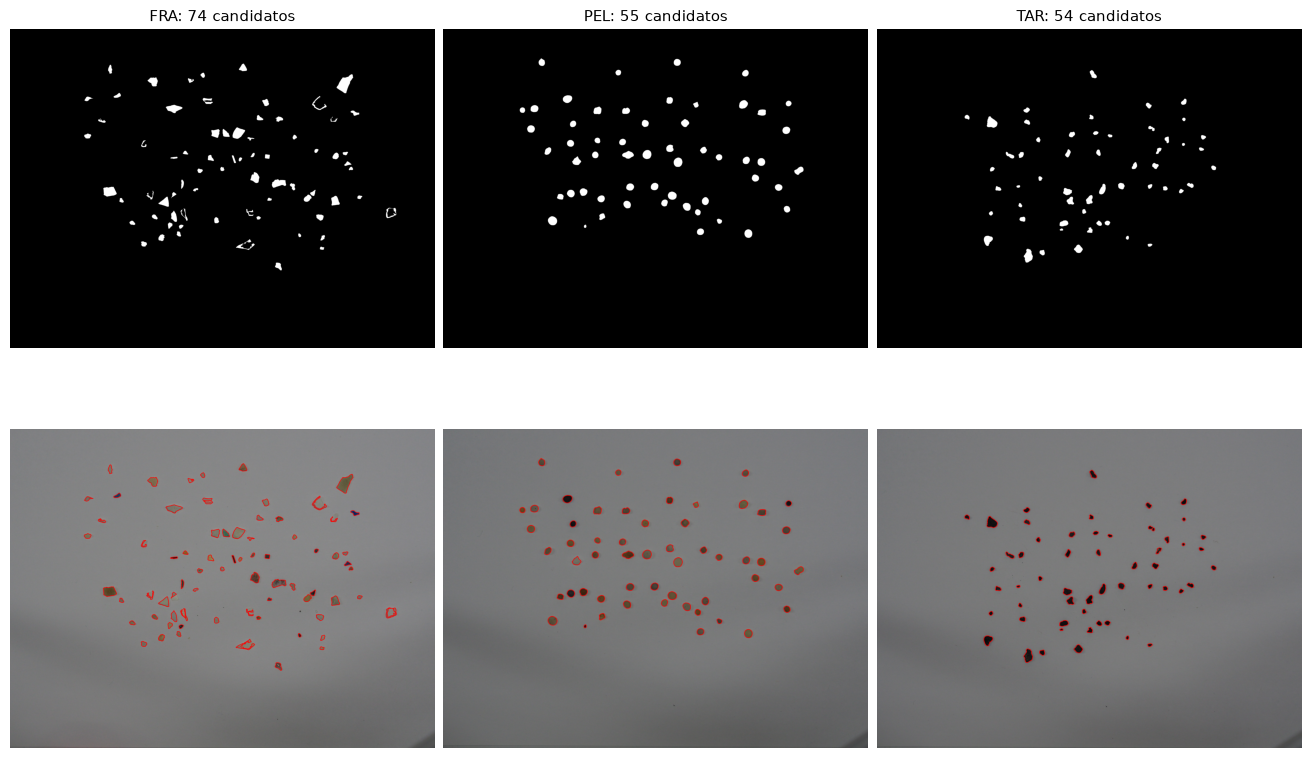

Total de candidatos medidos: 183


In [2]:
def obtener_contornos(mascara, area_minima):
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    validos = []
    for contorno in contornos:
        x, y, ancho, alto = cv2.boundingRect(contorno)
        if cv2.contourArea(contorno) < area_minima:
            continue  # Descarta zonas demasiado pequeñas.
        if x == 0 or y == 0 or x + ancho == mascara.shape[1] or y + alto == mascara.shape[0]:
            continue  # Descarta el marco y objetos cortados por el borde.
        validos.append(contorno)
    validos.sort(key=lambda contorno: cv2.boundingRect(contorno)[1])
    siluetas = np.zeros_like(mascara)
    cv2.drawContours(siluetas, validos, -1, 255, -1)
    return siluetas, validos

def medir_geometria(contorno):
    area = cv2.contourArea(contorno)
    perimetro = cv2.arcLength(contorno, True)
    momentos = cv2.moments(contorno)
    if area <= 0 or momentos['m00'] == 0:
        return None
    _, _, ancho, alto = cv2.boundingRect(contorno)
    centro = (momentos['m10'] / momentos['m00'], momentos['m01'] / momentos['m00'])
    distancia_menor = abs(cv2.pointPolygonTest(contorno, centro, True))
    puntos = contorno[:, 0, :].astype(float)
    distancia_mayor = np.sqrt(np.sum((puntos - centro)**2, axis=1)).max()
    relacion_ejes = np.nan  # Ajustar una elipse requiere al menos cinco puntos.
    if len(contorno) >= 5:
        _, ejes, _ = cv2.fitEllipse(contorno)
        if min(ejes) > 0:
            relacion_ejes = min(ejes) / max(ejes)
    return {'area_px2': area, 'perimetro_px': perimetro, 'compacidad': perimetro**2 / area,
            'ocupacion_contenedor': area / (ancho * alto), 'relacion_ancho_alto': ancho / alto,
            'relacion_ejes_elipse': relacion_ejes, 'relacion_distancias': distancia_menor / distancia_mayor}


def medir_apariencia(gris, saturacion, siluetas, contorno, referencia_oscura):
    x, y, ancho, alto = cv2.boundingRect(contorno)
    margen = max(3, round(0.10 * max(ancho, alto)))
    x1, y1 = max(0, x - margen), max(0, y - margen)
    x2, y2 = min(gris.shape[1], x + ancho + margen), min(gris.shape[0], y + alto + margen)
    recorte = gris[y1:y2, x1:x2]
    mascara = np.zeros_like(recorte)
    # Pasamos el contorno a las coordenadas del recorte.
    cv2.drawContours(mascara, [contorno - (x1, y1)], -1, 255, -1)
    dilatada = cv2.dilate(mascara, np.ones((2 * margen + 1, 2 * margen + 1), np.uint8))
    anillo = (dilatada > 0) & (siluetas[y1:y2, x1:x2] == 0)
    if not np.any(anillo):
        raise ValueError('No hay fondo cercano libre para medir esta partícula')
    gris_particula = float(np.percentile(recorte[mascara > 0], 25))
    gris_fondo = float(np.median(recorte[anillo]))
    gris_corregido = np.clip((gris_particula - referencia_oscura) / max(gris_fondo - referencia_oscura, 1), 0, 1)
    saturacion_media = cv2.mean(saturacion[y1:y2, x1:x2], mask=mascara)[0] / 255
    return {'gris_corregido': float(gris_corregido), 'saturacion_media': saturacion_media,
            'gris_particula': gris_particula, 'gris_fondo': gris_fondo, 'referencia_oscura': referencia_oscura}


muestras_entrenamiento = []
figura, ejes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
for columna, (clase, imagen) in enumerate(imagenes_entrenamiento.items()):
    gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
    saturacion = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)[:, :, 1]
    referencia_oscura = float(gris.min())
    suavizada = cv2.GaussianBlur(gris, (5, 5), 0)
    mascara = cv2.adaptiveThreshold(suavizada, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY_INV, 151, 5)
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    siluetas, contornos = obtener_contornos(mascara, area_minima=500)
    for numero, contorno in enumerate(contornos, start=1):
        medidas = medir_geometria(contorno)
        if medidas is not None:
            medidas.update(medir_apariencia(gris, saturacion, siluetas, contorno, referencia_oscura))
            muestras_entrenamiento.append({'clase': clase, 'id': numero, **medidas})
    marcada = imagen.copy()
    cv2.drawContours(marcada, contornos, -1, (0, 0, 255), 5)
    ejes[0, columna].imshow(siluetas, cmap='gray', vmin=0, vmax=255)
    ejes[0, columna].set_title(f'{clase}: {len(contornos)} candidatos')
    ejes[1, columna].imshow(cv2.cvtColor(marcada, cv2.COLOR_BGR2RGB))
    cv2.imwrite(str(carpeta_resultados / f'{clase}_mascara.png'), siluetas)
for eje in ejes.flat:
    eje.axis('off')
figura.savefig(carpeta_resultados / 'entrenamiento.png', dpi=130)
plt.show()
guardar_csv('caracteristicas_entrenamiento.csv', muestras_entrenamiento)
print(f'Total de candidatos medidos: {len(muestras_entrenamiento)}')

### Paso 3. Reglas de características para FRA, PEL y TAR

Una vez obtenidas las siete medidas de forma, además del gris corregido y saturación media, a continuación, para decidir qué tipo de fragmento se va a predecir, usaremos **cinco medidas**: compacidad, relación de distancias, ocupación del rectángulo, gris corregido y saturación media.

Aplicamos estas condiciones **en este orden**. La primera que se cumple decide la clase:

| Orden | Condición | Resultado |
|---|---|---|
| 1 | Gris corregido ≤ 0,30 **y** saturación ≤ 0,10 | TAR muy oscuro y casi sin color, incluso si es redondeado. |
| 2 | Relación de distancias ≥ 0,70 **y** compacidad ≤ 16; **o bien** ocupación del rectángulo ≥ 0,75 **y** compacidad ≤ 16,5 | PEL: forma redondeada o compacta que llena bien su rectángulo. |
| 3 | Si no cumplió las condiciones 1 y 2: gris corregido ≤ 0,50 **y** saturación ≤ 0,30 | TAR oscuro que no ha mostrado la forma de PEL. |
| 4 | Resto de los casos | FRA. |

La primera condición permite encontrar alquitrán negro sin obligarle a ser irregular. Su límite de saturación es estricto para no tomar como alquitrán cualquier pellet oscuro que conserve color. La condición de PEL protege los pellets algo oscuros pero redondeados. La segunda condición TAR admite alquitrán menos negro, siempre que no tenga demasiado color ni haya cumplido la condición de PEL. **Los dos caminos hacia TAR exigen oscuridad: una partícula clara nunca recibe esa clase.** Todavía puede haber pellets negros o fragmentos oscuros que cumplan una condición TAR; son los límites de estas reglas, pues no son perfectas.


In [3]:
resumen_entrenamiento = []
print('Clase / medida: percentil 25, mediana, percentil 75, percentil 90')
for clase in clases:
    for nombre in ['compacidad', 'relacion_distancias', 'ocupacion_contenedor', 'gris_corregido', 'saturacion_media']:
        valores = [fila[nombre] for fila in muestras_entrenamiento if fila['clase'] == clase]
        q25, mediana, q75, p90 = np.percentile(valores, [25, 50, 75, 90])
        resumen_entrenamiento.append({'clase': clase, 'medida': nombre, 'q25': q25,
                                      'mediana': mediana, 'q75': q75, 'p90': p90})
        print(f'{clase} / {nombre}: {q25:.3f}, {mediana:.3f}, {q75:.3f}, {p90:.3f}')
guardar_csv('resumen_entrenamiento.csv', resumen_entrenamiento)

def clasificar_por_reglas(medidas):
    gris = medidas['gris_corregido']
    saturacion = medidas['saturacion_media']
    compacidad = medidas['compacidad']
    distancias = medidas['relacion_distancias']
    ocupacion = medidas['ocupacion_contenedor']
    if not np.isfinite([gris, saturacion, compacidad, distancias, ocupacion]).all():
        raise ValueError('Faltan medidas válidas para clasificar')
    if gris <= 0.30 and saturacion <= 0.10:
        return 'TAR'  # Muy oscura y con poco color: no se exige una forma concreta.
    if (distancias >= 0.70 and compacidad <= 16) or (ocupacion >= 0.75 and compacidad <= 16.5):
        return 'PEL'  # Redondeada o compacta; conserva pellets de oscuridad moderada.
    if gris <= 0.50 and saturacion <= 0.30:
        return 'TAR'  # Oscura, poco coloreada y no ha cumplido la condición de pellet.
    return 'FRA'

# La función recibe las medidas, nunca la clase real ni el identificador.
reales_entrenamiento = [fila['clase'] for fila in muestras_entrenamiento]
predichas_entrenamiento = [clasificar_por_reglas({k: v for k, v in fila.items() if k not in ['clase', 'id']})
                          for fila in muestras_entrenamiento]
matriz_entrenamiento = confusion_matrix(reales_entrenamiento, predichas_entrenamiento, labels=clases)
aciertos_entrenamiento = int(np.trace(matriz_entrenamiento))
print(f'\nEntrenamiento: {aciertos_entrenamiento}/{len(muestras_entrenamiento)} aciertos '
      f'({100 * aciertos_entrenamiento / len(muestras_entrenamiento):.1f} %)')
print('Filas: clase real; columnas: FRA, PEL, TAR')
print(matriz_entrenamiento)

Clase / medida: percentil 25, mediana, percentil 75, percentil 90
FRA / compacidad: 16.749, 18.596, 25.521, 76.530
FRA / relacion_distancias: 0.278, 0.433, 0.571, 0.633
FRA / ocupacion_contenedor: 0.508, 0.633, 0.675, 0.714
FRA / gris_corregido: 0.557, 0.776, 0.828, 0.861
FRA / saturacion_media: 0.094, 0.138, 0.264, 0.409
PEL / compacidad: 14.299, 14.462, 14.865, 15.878
PEL / relacion_distancias: 0.735, 0.832, 0.871, 0.894
PEL / ocupacion_contenedor: 0.738, 0.757, 0.769, 0.782
PEL / gris_corregido: 0.491, 0.591, 0.667, 0.696
PEL / saturacion_media: 0.239, 0.317, 0.414, 0.548
TAR / compacidad: 15.379, 16.009, 16.973, 18.354
TAR / relacion_distancias: 0.488, 0.553, 0.653, 0.746
TAR / ocupacion_contenedor: 0.648, 0.677, 0.706, 0.744
TAR / gris_corregido: 0.106, 0.134, 0.158, 0.200
TAR / saturacion_media: 0.076, 0.086, 0.096, 0.113

Entrenamiento: 162/183 aciertos (88.5 %)
Filas: clase real; columnas: FRA, PEL, TAR
[[65  1  8]
 [ 6 44  5]
 [ 0  1 53]]


### Paso 4. Encontrar y clasificar las partículas del test

La imagen de prueba tiene otro tamaño y un fondo menos uniforme. Para separar las partículas combinamos zonas oscuras, coloreadas y casi blancas:

1. Pasamos a gris y suavizamos con **5 × 5**. Un suavizado mayor, de **51 × 51**, da una referencia aproximada del fondo cercano.
2. Marcamos las zonas **más oscuras que esa referencia por más de 8** niveles. `subtract` deja a cero las diferencias negativas y evita que aparezcan valores incorrectos al restar imágenes de 8 bits.
3. Añadimos zonas con **saturación > 25**. La saturación es el canal S de HSV y señala cuánto color tiene un píxel; así recuperamos objetos coloreados con poco contraste en gris.
4. Añadimos zonas con **gris suavizado > 245**, para incluir partículas casi blancas.
5. Unimos las tres máscaras con `bitwise_or`, aplicamos un cierre **elíptico de 3 × 3** y conservamos contornos de **área ≥ 50 píxeles²** que no tocan el borde. A este tamaño, el elemento elíptico tiene forma de cruz.

El área mínima es menor porque las partículas del test aparecen más pequeñas. Estos valores se aplican a esta fotografía; pueden necesitar cambios con otra iluminación o resolución. El cierre ayuda con pequeños cortes, pero también puede unir objetos cercanos.

Después medimos **las mismas siete características de forma y las dos de apariencia** y aplicamos **exactamente las reglas del paso 3**. En este punto guardamos las predicciones sin consultar el CSV de anotaciones. Encontrar un contorno no garantiza que sea una partícula completa ni que su clase sea correcta.

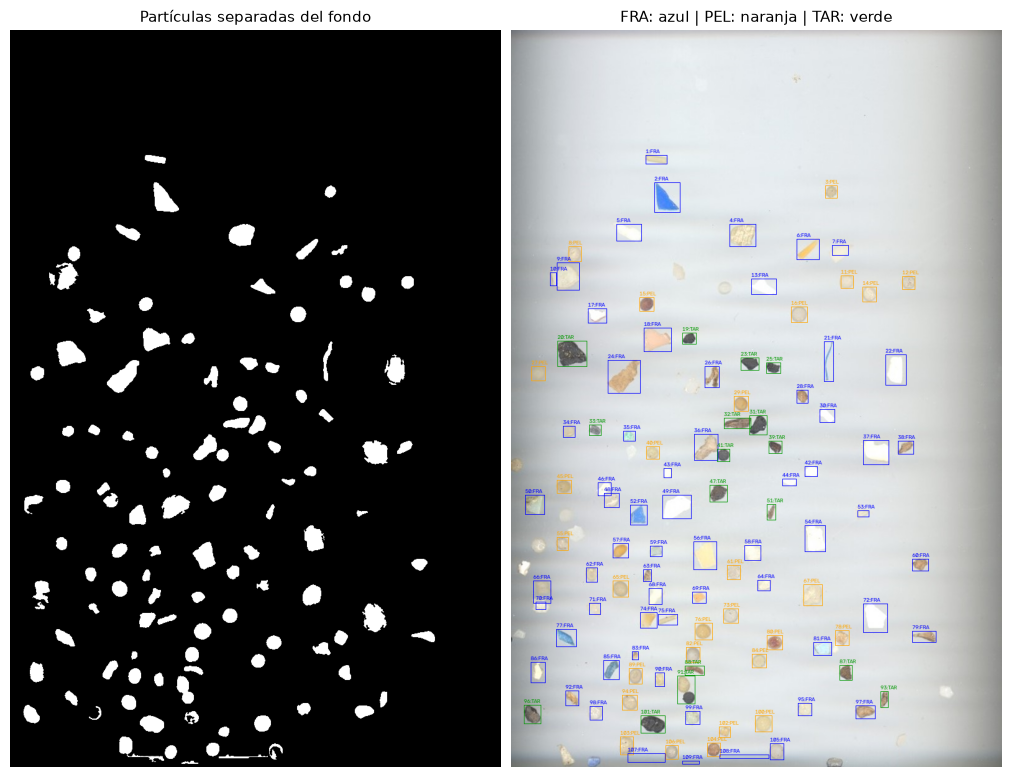

Candidatos encontrados: 109
FRA: 64
PEL: 28
TAR: 17


In [4]:
gris_test = cv2.cvtColor(imagen_test, cv2.COLOR_BGR2GRAY)
suavizada_test = cv2.GaussianBlur(gris_test, (5, 5), 0)
fondo_test = cv2.GaussianBlur(suavizada_test, (51, 51), 0)
diferencia_oscura = cv2.subtract(fondo_test, suavizada_test)
saturacion_test = cv2.cvtColor(imagen_test, cv2.COLOR_BGR2HSV)[:, :, 1]
_, oscuras = cv2.threshold(diferencia_oscura, 8, 255, cv2.THRESH_BINARY)
_, coloreadas = cv2.threshold(saturacion_test, 25, 255, cv2.THRESH_BINARY)
_, claras = cv2.threshold(suavizada_test, 245, 255, cv2.THRESH_BINARY)
mascara_test = cv2.bitwise_or(cv2.bitwise_or(oscuras, coloreadas), claras)
elemento = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
mascara_test = cv2.morphologyEx(mascara_test, cv2.MORPH_CLOSE, elemento)
siluetas_test, contornos_test = obtener_contornos(mascara_test, area_minima=50)

referencia_oscura_test = float(gris_test.min())
predicciones_test = []
for contorno in contornos_test:
    medidas = medir_geometria(contorno)
    if medidas is None:
        continue
    medidas.update(medir_apariencia(gris_test, saturacion_test, siluetas_test, contorno, referencia_oscura_test))
    x, y, ancho, alto = cv2.boundingRect(contorno)
    predicciones_test.append({'id': len(predicciones_test) + 1,
        'clase_predicha': clasificar_por_reglas(medidas), 'x_min': x, 'y_min': y,
        'x_max': x + ancho, 'y_max': y + alto, **medidas})
guardar_csv('predicciones_test.csv', predicciones_test)
# Los colores son solo para mostrar las clases que ya hemos predicho.
colores = {'FRA': (255, 0, 0), 'PEL': (0, 165, 255), 'TAR': (0, 150, 0)}
imagen_resultado = imagen_test.copy()
for fila in predicciones_test:
    x1, y1, x2, y2 = [fila[k] for k in ['x_min', 'y_min', 'x_max', 'y_max']]
    color = colores[fila['clase_predicha']]
    cv2.rectangle(imagen_resultado, (x1, y1), (x2, y2), color, 1)
    cv2.putText(imagen_resultado, f"{fila['id']}:{fila['clase_predicha']}", (x1, max(12, y1 - 3)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.3, color, 1, cv2.LINE_AA)
figura, ejes = plt.subplots(1, 2, figsize=(10, 10), constrained_layout=True)
ejes[0].imshow(siluetas_test, cmap='gray', vmin=0, vmax=255)
ejes[0].set_title('Partículas separadas del fondo')
ejes[1].imshow(cv2.cvtColor(imagen_resultado, cv2.COLOR_BGR2RGB))
ejes[1].set_title('FRA: azul | PEL: naranja | TAR: verde')
for eje in ejes:
    eje.axis('off')
figura.savefig(carpeta_resultados / 'resultado_test.png', dpi=150)
plt.show()
cv2.imwrite(str(carpeta_resultados / 'mascara_test.png'), siluetas_test)
cv2.imwrite(str(carpeta_resultados / 'test_clasificado.png'), imagen_resultado)
print(f'Candidatos encontrados: {len(predicciones_test)}')
for clase in clases:
    print(f"{clase}: {sum(fila['clase_predicha'] == clase for fila in predicciones_test)}")

### Paso 5. Comprobar los aciertos y los errores

Ahora sí leemos `MPs_test_bbs.csv`, que indica la clase y el rectángulo de cada partícula real. Las anotaciones sirven para **comprobar**, no para dar la respuesta al clasificador.

Para decidir si hemos encontrado una partícula comparamos su rectángulo real con uno detectado. Usamos **IoU**: área que comparten dividida entre el área total que cubren ambos. Vale 1 si coinciden y 0 si no se tocan. Admitimos parejas con **IoU ≥ 0,50**. 

En este punto, nos hacemos dos preguntas:

- **Detección:** ¿hemos localizado la partícula, sin importar la clase que hemos predicho?
- **Clasificación:** entre las partículas localizadas, ¿hemos acertado con su clase FRA, PEL o TAR?

La matriz de confusión tiene las **clases reales en las filas** y las **predichas en las columnas**, en orden FRA, PEL, TAR. Su diagonal contiene los aciertos. La primera matriz solo incluye parejas; la segunda añade las anotaciones sin pareja y las detecciones sobrantes. La casilla inferior derecha de esta última no tiene significado y se muestra con un guion.

Para las métricas usamos estos recuentos: **TP** son los aciertos, **FP** son resultados que damos de más (Falsos Positivos) y **FN** son casos que no acertamos.

| Medida | Explicación sencilla |
|---|---|
| Precisión = TP / (TP + FP) | De lo que damos como resultado, qué parte está bien. |
| Recall = TP / (TP + FN) | De lo que había que encontrar o reconocer, qué parte conseguimos. |
| F1 = 2·TP / (2·TP + FP + FN) | Combina precisión y recall. Cerca de 1 es mejor. |
| F1 macro completo | Media del F1 de FRA, PEL y TAR, dando el mismo peso a cada clase. |
| Exactitud de las parejas | Clases correctas divididas entre las partículas localizadas. |
| Aciertos completos sobre todas las anotaciones | Partículas bien localizadas y clasificadas, divididas entre todas las reales. Debe acompañarse de las otras métricas porque no penaliza por sí sola los sobrantes. |

In [5]:
def calcular_iou(caja_a, caja_b):
    x1, y1 = max(caja_a[0], caja_b[0]), max(caja_a[1], caja_b[1])
    x2, y2 = min(caja_a[2], caja_b[2]), min(caja_a[3], caja_b[3])
    interseccion = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = (caja_a[2] - caja_a[0]) * (caja_a[3] - caja_a[1])
    area_b = (caja_b[2] - caja_b[0]) * (caja_b[3] - caja_b[1])
    union = area_a + area_b - interseccion
    return interseccion / union if union > 0 else 0.0

def asociar_cajas(cajas_reales, cajas_detectadas):
    candidatas = []
    for i, caja_real in enumerate(cajas_reales):
        for j, caja_detectada in enumerate(cajas_detectadas):
            iou = calcular_iou(caja_real, caja_detectada)
            if iou >= 0.50:
                candidatas.append((i, j, iou))
    candidatas.sort(key=lambda pareja: pareja[2], reverse=True)
    reales_usadas, detectadas_usadas, parejas = set(), set(), []
    for i, j, iou in candidatas:
        if i not in reales_usadas and j not in detectadas_usadas:
            parejas.append((i, j, iou))
            reales_usadas.add(i)
            detectadas_usadas.add(j)
    return parejas

with open('MPs_test_bbs.csv', newline='', encoding='utf-8-sig') as archivo:
    anotaciones = list(csv.DictReader(archivo))
campos_caja = ['x_min', 'y_min', 'x_max', 'y_max']
cajas_reales = [tuple(int(fila[k]) for k in campos_caja) for fila in anotaciones]
cajas_detectadas = [tuple(fila[k] for k in campos_caja) for fila in predicciones_test]
for anotacion, (x1, y1, x2, y2) in zip(anotaciones, cajas_reales):
    if anotacion['label'] not in clases or not (0 <= x1 < x2 <= imagen_test.shape[1] and 0 <= y1 < y2 <= imagen_test.shape[0]):
        raise ValueError('Hay una anotación con clase o coordenadas incorrectas')
parejas = asociar_cajas(cajas_reales, cajas_detectadas)
reales = [anotaciones[i]['label'] for i, j, iou in parejas]
predichas = [predicciones_test[j]['clase_predicha'] for i, j, iou in parejas]
matriz = confusion_matrix(reales, predichas, labels=clases)
aciertos = int(np.trace(matriz))

def calcular_metricas(tp, fp, fn):
    return {'tp': tp, 'fp': fp, 'fn': fn,
            'precision': tp / (tp + fp) if tp + fp else 0,
            'recall': tp / (tp + fn) if tp + fn else 0,
            'f1': 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0}

deteccion = calcular_metricas(len(parejas), len(predicciones_test) - len(parejas), len(anotaciones) - len(parejas))
metricas = [{'alcance': 'deteccion', 'clase': 'GLOBAL', **deteccion}]
matriz_completa = np.zeros((4, 4), dtype=int)
matriz_completa[:3, :3] = matriz
for indice, clase in enumerate(clases):
    total_real = sum(fila['label'] == clase for fila in anotaciones)
    total_predicho = sum(fila['clase_predicha'] == clase for fila in predicciones_test)
    tp = int(matriz[indice, indice])
    metricas.append({'alcance': 'proceso_completo', 'clase': clase,
                    **calcular_metricas(tp, total_predicho - tp, total_real - tp)})
    matriz_completa[indice, 3] = total_real - int(matriz[indice, :].sum())
    matriz_completa[3, indice] = total_predicho - int(matriz[:, indice].sum())
f1_macro = np.mean([fila['f1'] for fila in metricas[1:]])
exactitud_parejas = aciertos / len(parejas) if parejas else 0
aciertos_totales = aciertos / len(anotaciones) if anotaciones else 0
guardar_csv('metricas_test.csv', metricas)
guardar_csv('resumen_test.csv', [{'anotaciones': len(anotaciones), 'detecciones': len(predicciones_test),
    'parejas': len(parejas), 'aciertos': aciertos, 'sin_pareja_real': deteccion['fn'],
    'sobrantes': deteccion['fp'], 'exactitud_parejas': exactitud_parejas,
    'aciertos_sobre_todas': aciertos_totales, 'f1_macro_completo': f1_macro}])
guardar_csv('asociaciones_test.csv', [{'id_anotacion': i + 1, 'id_deteccion': predicciones_test[j]['id'],
    'clase_real': anotaciones[i]['label'], 'clase_predicha': predicciones_test[j]['clase_predicha'], 'iou': iou}
    for i, j, iou in parejas])

print(f'Anotaciones: {len(anotaciones)} | Detecciones: {len(predicciones_test)} | Parejas: {len(parejas)}')
print(f"Sin pareja real: {deteccion['fn']} | Detecciones sobrantes: {deteccion['fp']}")
print(f'Clases correctas entre las parejas: {aciertos}/{len(parejas)} = {100 * exactitud_parejas:.1f} %')
print(f'Aciertos completos sobre todas las anotaciones: {aciertos}/{len(anotaciones)} = {100 * aciertos_totales:.1f} %')
print(f'F1 macro completo: {f1_macro:.3f}\n')
print(f"{'Alcance / clase':<27} {'Precisión':>10} {'Recall':>10} {'F1':>10}")
for fila in metricas:
    nombre = f"{fila['alcance']} / {fila['clase']}"
    print(f"{nombre:<27} {fila['precision']:>10.3f} {fila['recall']:>10.3f} {fila['f1']:>10.3f}")

Anotaciones: 120 | Detecciones: 109 | Parejas: 89
Sin pareja real: 31 | Detecciones sobrantes: 20
Clases correctas entre las parejas: 76/89 = 85.4 %
Aciertos completos sobre todas las anotaciones: 76/120 = 63.3 %
F1 macro completo: 0.700

Alcance / clase              Precisión     Recall         F1
deteccion / GLOBAL               0.817      0.742      0.777
proceso_completo / FRA           0.625      0.606      0.615
proceso_completo / PEL           0.821      0.605      0.697
proceso_completo / TAR           0.765      0.812      0.788


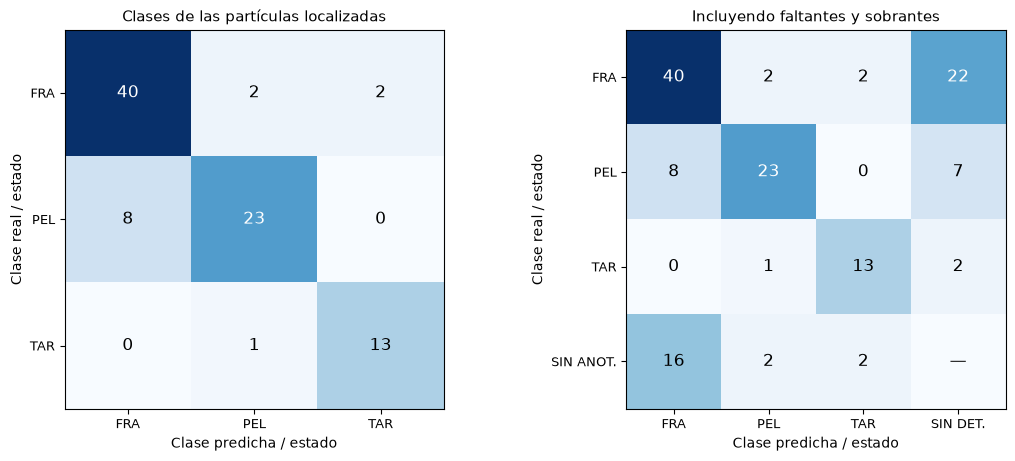

In [6]:
figura, ejes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for eje, datos, titulo in zip(ejes, [matriz, matriz_completa],
                              ['Clases de las partículas localizadas', 'Incluyendo faltantes y sobrantes']):
    ampliada = len(datos) == 4
    eje.imshow(datos, cmap='Blues', vmin=0)
    eje.set_xticks(range(len(datos)), [*clases, 'SIN DET.'] if ampliada else clases)
    eje.set_yticks(range(len(datos)), [*clases, 'SIN ANOT.'] if ampliada else clases)
    eje.set(xlabel='Clase predicha / estado', ylabel='Clase real / estado', title=titulo)
    for i, fila in enumerate(datos):
        for j, valor in enumerate(fila):
            texto = '—' if ampliada and i == j == 3 else str(valor)
            eje.text(j, i, texto, ha='center', va='center',
                     color='white' if valor > datos.max() / 2 else 'black', fontsize=12)
figura.savefig(carpeta_resultados / 'matrices_confusion.png', dpi=150)
plt.show()

**Cómo interpretar los resultados**

El proceso encuentra **109 candidatos**, de los que **89** se emparejan con las 120 anotaciones. Entre estas parejas se aciertan **76 clases**: **40 FRA, 23 PEL y 13 TAR**. Esto supone un **85,4 %** de clases correctas entre las localizadas y un **63,3 %** de aciertos completos sobre todas las partículas anotadas.

Hay **13 confusiones de clase**, **31 anotaciones sin pareja** y **20 detecciones sobrantes**. Por eso es importante contar también las partículas que faltan y los resultados que sobran, además de revisar las etiquetas acertadas.

La detección obtiene precisión **0,817**, recall **0,742** y F1 **0,777**. El F1 macro del proceso completo es **0,700**. Las tablas de resumen muestran el detalle por clase.

**Límites del método:** los objetos oscuros también pueden ser fragmentos o pellets; la oscuridad no garantiza que un material sea alquitrán. La referencia de gris mínimo es aproximada y puede cambiar por ruido. Solo disponemos de una fotografía de entrenamiento por clase, y la evaluación corresponde a una imagen utilizada para ajustar los parámetros. Para comprobar el comportamiento en una evaluación independiente se necesitan otras fotografías anotadas.


**Resumen de resultados sobre las anotaciones del test**

El resumen cuenta las **120 partículas de `MPs_test_bbs.csv`**, incluidas las que no se localizaron, y también las detecciones sobrantes. «Localizada» significa que obtuvo una pareja con una anotación (IoU ≥ 0,50); «bien identificada» exige además acertar la clase.

Las métricas por clase incluyen los objetos no localizados y las predicciones incorrectas o sobrantes. Las tablas se calculan a partir de las predicciones del cuaderno y se actualizan al ejecutarlo.

En la tabla de confusión, las filas indican la clase real y las columnas la clase predicha. La fila «Sin anotación» recoge detecciones sobrantes y no forma parte de las 120 partículas reales.


In [9]:
from IPython.display import Markdown, display

def mostrar_tabla_resumen(titulo, columnas, filas):
    tabla = [f'**{titulo}**', '', '| ' + ' | '.join(columnas) + ' |',
             '| ' + ' | '.join(['---'] * len(columnas)) + ' |']
    tabla.extend('| ' + ' | '.join(str(valor) for valor in fila) + ' |' for fila in filas)
    display(Markdown(chr(10).join(tabla)))

def porcentaje_resumen(valor):
    return f'{100 * valor:.2f} %'.replace('.', ',')

total_reales, total_detectadas, total_localizadas = len(anotaciones), len(predicciones_test), len(parejas)
# Aquí un acierto exige localizar la partícula y acertar su clase.
metricas_globales = calcular_metricas(aciertos, total_detectadas - aciertos, total_reales - aciertos)
filas_totales = [
    ['Partículas anotadas', total_reales],
    ['Candidatos detectados (incluyen sobrantes)', total_detectadas],
    ['Partículas localizadas / total real', f'{total_localizadas}/{total_reales} ({porcentaje_resumen(deteccion["recall"])})'],
    ['Partículas sin localizar', deteccion['fn']],
    ['Detecciones sobrantes', deteccion['fp']],
    ['Bien localizadas y clasificadas / total real', f'{aciertos}/{total_reales} ({porcentaje_resumen(aciertos_totales)})'],
    ['Localizadas con clase equivocada', total_localizadas - aciertos],
    ['Anotadas sin acierto completo (perdidas + mal clasificadas)', total_reales - aciertos],
    ['Exactitud entre las localizadas', porcentaje_resumen(exactitud_parejas)],
    ['Precisión global (localización y clase)', porcentaje_resumen(metricas_globales['precision'])],
    ['Recall global (localización y clase)', porcentaje_resumen(metricas_globales['recall'])],
    ['F1 global (micro)', f'{metricas_globales["f1"]:.3f}'],
    ['F1 macro (media de las tres clases)', f'{f1_macro:.3f}']]
for medida, nombre in [('precision', 'Precisión'), ('recall', 'Recall'), ('f1', 'F1')]:
    valor = porcentaje_resumen(deteccion[medida]) if medida != 'f1' else f'{deteccion[medida]:.3f}'
    filas_totales.append([f'{nombre} de detección (sin exigir clase)', valor])
mostrar_tabla_resumen('1. Resumen de todas las partículas', ['Medida', 'Resultado'], filas_totales)

filas_clases, filas_metricas, filas_confusion = [], [], []
for indice, clase in enumerate(clases):
    total_clase = sum(fila['label'] == clase for fila in anotaciones)
    localizadas = int(matriz[indice, :].sum())
    filas_clases.append([clase, total_clase, localizadas, total_clase - localizadas,
                         int(matriz[indice, indice]), localizadas - int(matriz[indice, indice])])
    resultado_clase = next(fila for fila in metricas if fila['clase'] == clase)
    filas_metricas.append([clase, resultado_clase['tp'], resultado_clase['fp'], resultado_clase['fn'],
        porcentaje_resumen(resultado_clase['precision']), porcentaje_resumen(resultado_clase['recall']),
        f'{resultado_clase["f1"]:.3f}'])
    filas_confusion.append([clase, *[int(matriz[indice, j]) for j in range(3)],
                            total_clase - localizadas, total_clase])
filas_confusion.append(['Sin anotación', *[int(matriz_completa[3, j]) for j in range(3)],
                        '—', f'{deteccion["fp"]} sobrantes'])
mostrar_tabla_resumen('2. Recuento por clase real',
    ['Clase', 'Anotadas', 'Localizadas', 'Sin localizar', 'Bien identificadas', 'Clase equivocada'], filas_clases)
mostrar_tabla_resumen('3. Métricas del proceso completo por clase',
    ['Clase', 'TP', 'FP', 'FN', 'Precisión', 'Recall', 'F1'], filas_metricas)
mostrar_tabla_resumen('4. Matriz de confusión con faltantes y sobrantes',
    ['Clase real', 'Pred. FRA', 'Pred. PEL', 'Pred. TAR', 'Sin localizar', 'Total'], filas_confusion)


**1. Resumen de todas las partículas**

| Medida | Resultado |
| --- | --- |
| Partículas anotadas | 120 |
| Candidatos detectados (incluyen sobrantes) | 109 |
| Partículas localizadas / total real | 89/120 (74,17 %) |
| Partículas sin localizar | 31 |
| Detecciones sobrantes | 20 |
| Bien localizadas y clasificadas / total real | 76/120 (63,33 %) |
| Localizadas con clase equivocada | 13 |
| Anotadas sin acierto completo (perdidas + mal clasificadas) | 44 |
| Exactitud entre las localizadas | 85,39 % |
| Precisión global (localización y clase) | 69,72 % |
| Recall global (localización y clase) | 63,33 % |
| F1 global (micro) | 0.664 |
| F1 macro (media de las tres clases) | 0.700 |
| Precisión de detección (sin exigir clase) | 81,65 % |
| Recall de detección (sin exigir clase) | 74,17 % |
| F1 de detección (sin exigir clase) | 0.777 |

**2. Recuento por clase real**

| Clase | Anotadas | Localizadas | Sin localizar | Bien identificadas | Clase equivocada |
| --- | --- | --- | --- | --- | --- |
| FRA | 66 | 44 | 22 | 40 | 4 |
| PEL | 38 | 31 | 7 | 23 | 8 |
| TAR | 16 | 14 | 2 | 13 | 1 |

**3. Métricas del proceso completo por clase**

| Clase | TP | FP | FN | Precisión | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| FRA | 40 | 24 | 26 | 62,50 % | 60,61 % | 0.615 |
| PEL | 23 | 5 | 15 | 82,14 % | 60,53 % | 0.697 |
| TAR | 13 | 4 | 3 | 76,47 % | 81,25 % | 0.788 |

**4. Matriz de confusión con faltantes y sobrantes**

| Clase real | Pred. FRA | Pred. PEL | Pred. TAR | Sin localizar | Total |
| --- | --- | --- | --- | --- | --- |
| FRA | 40 | 2 | 2 | 22 | 66 |
| PEL | 8 | 23 | 0 | 7 | 38 |
| TAR | 0 | 1 | 13 | 2 | 16 |
| Sin anotación | 16 | 2 | 2 | — | 20 sobrantes |

**Matriz de confusión de clasificación**

Las filas indican la clase real y las columnas la clase predicha. Los números de la diagonal son las partículas bien clasificadas: **40 FRA, 23 PEL y 13 TAR**.

Esta matriz incluye las **89 partículas localizadas** que tienen pareja con una anotación (IoU ≥ 0,50). De ellas, **76 se clasifican correctamente** y 13 reciben una clase equivocada. Las 31 anotaciones sin pareja y las 20 detecciones sobrantes se recogen en el resumen de resultados; no aparecen en esta matriz de tres clases. En total, el proceso localiza y clasifica bien **76 de las 120 partículas anotadas**.


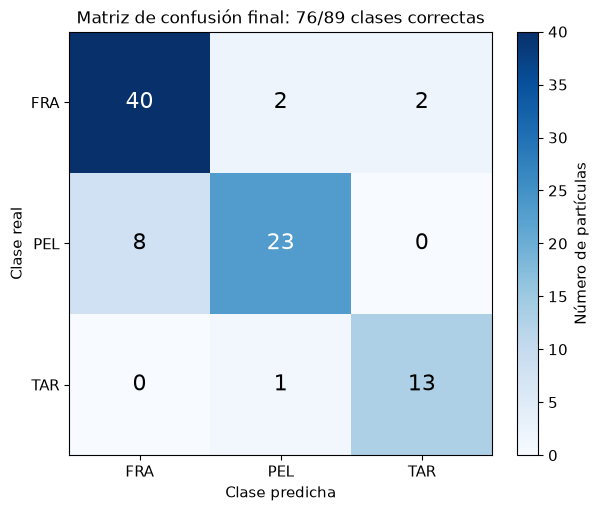

In [8]:
# Calculamos la matriz a partir de las predicciones y sus parejas con las anotaciones.
clases_reales_finales = [anotaciones[i]['label'] for i, j, iou in parejas]
clases_predichas_finales = [predicciones_test[j]['clase_predicha'] for i, j, iou in parejas]
matriz_final = confusion_matrix(clases_reales_finales, clases_predichas_finales, labels=clases)
aciertos_finales = int(np.trace(matriz_final))

with plt.rc_context({'font.size': 11, 'axes.titlesize': 12, 'axes.labelsize': 11,
                     'xtick.labelsize': 11, 'ytick.labelsize': 11}):
    figura_final, eje_final = plt.subplots(figsize=(6, 5), constrained_layout=True)
    colores_matriz = eje_final.imshow(matriz_final, cmap='Blues', vmin=0)
    figura_final.colorbar(colores_matriz, ax=eje_final, label='Número de partículas')
    eje_final.set_xticks(range(3), clases)
    eje_final.set_yticks(range(3), clases)
    eje_final.set(xlabel='Clase predicha', ylabel='Clase real',
                  title=f'Matriz de confusión final: {aciertos_finales}/{len(parejas)} clases correctas')
    for fila in range(3):
        for columna in range(3):
            valor = matriz_final[fila, columna]
            eje_final.text(columna, fila, str(valor), ha='center', va='center', fontsize=16,
                           color='white' if valor > matriz_final.max() / 2 else 'black')
    figura_final.savefig(carpeta_resultados / 'matriz_confusion_final.png', dpi=150)
    plt.show()


---